# Stock Price Prediction: Linear Regression -> LSTM

Uses `data-02-stock_daily - data-02-stock_daily.csv` (must be in the same folder): daily Google (GOOG) stock history with the columns
*Open, High, Low, Volume, Close*. The model predicts the **next day's Close** from today's Open/High/Low/Volume.

1. **Baseline** - a linear model predicts the next day's value from today's features
2. **Improved** - an **LSTM** reads a window of the previous 5 days (a sequence), which suits time-series data

Both models use Min-Max scaling and a chronological 70/30 train/test split.

Before shift:
[0.97333581 0.97543152 1.         0.11112306] [0.98831302]
[0.95690035 0.95988111 0.9803545  0.14250246] [0.97785024]
After shift:
[0.97333581 0.97543152 1.         0.11112306] [0.97785024]
[0.95690035 0.95988111 0.9803545  0.14250246] [0.96645463]


C:\Users\User\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 3.8039e-04 - mse: 3.8039e-04 
Test Loss, Test MSE: [0.0003803911677096039, 0.0003803911677096039]
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step


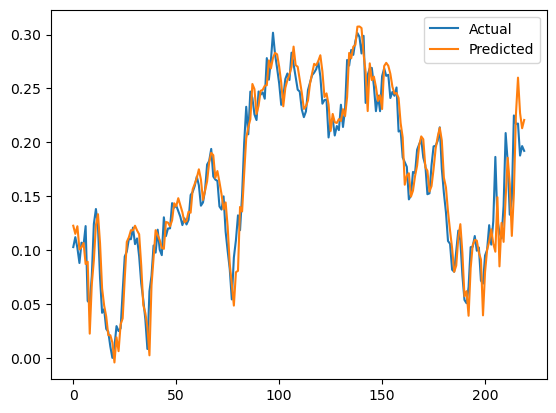

In [5]:
# Baseline: a single linear neuron predicts tomorrow's value from today's features.
from keras.models import Sequential
from keras.layers import Dense
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt

# Load dataset
xy = np.loadtxt("data-02-stock_daily - data-02-stock_daily.csv", delimiter=',')

# Normalize data
# scale every column to [0, 1] - Volume is in the millions while prices are in the hundreds, so unscaled data would be dominated by Volume
scaler = MinMaxScaler(feature_range=(0, 1))
xy = scaler.fit_transform(xy)

# Split features and labels
x_data = xy[:, 0:-1]   # all columns except last
y_data = xy[:, [-1]]   # last column only

print("Before shift:")
print(x_data[0], y_data[0])
print(x_data[1], y_data[1])

# Align data for "predict tomorrow"
x_data = np.delete(x_data, -1, axis=0)   # remove last row
y_data = np.delete(y_data, 0, axis=0)    # remove first row

print("After shift:")
print(x_data[0], y_data[0])
print(x_data[1], y_data[1])
